# ENVIRONMENT CONFIGURATION

In [4]:
import os
import sys
import json
import random
import shutil
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import csv
import yaml
from collections import Counter, defaultdict

import torch
from ultralytics import YOLO

In [8]:
# ==========================================================
# 1. RANDOMNESS AND TRAINING SEED
# ==========================================================
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def get_random(seed=SEED):
    """Get a Python Random instance with a given seed. Default to global seed."""
    
    return random.Random(seed)

set_seed(SEED)
print(f"Training seed: {SEED}")

Training seed: 42


In [9]:
# ==========================================================
# 2. ACCELERATED DEVICE DETECTION
# ==========================================================
if torch.cuda.is_available():
    DEVICE = 0
    device_desc = f"NVIDIA GPU ({torch.cuda.get_device_name(0)})"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
    device_desc = "Apple Silicon GPU (MPS)"
else:
    DEVICE = "cpu"
    device_desc = "CPU"

print(f"OS platform: {os.name}")
print("CPU Model: Intel i7-10700")
print(f"CPU name: {os.uname().sysname} {os.uname().release} {os.uname().version}")
print(f"CPU cores: {os.cpu_count()}")
print(f"RAM: {round(os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / (1024 ** 3), 2)} GB")
print(f"Python version: {sys.version}")
print(f"PyTorch version: {torch.__version__}")
print(f"OpenCV version: {cv2.__version__}")
print(f"Ultralytics YOLO loaded")
print(f"Using device: {DEVICE} ({device_desc})")
print(f"VRAM available: {round(torch.cuda.get_device_properties(0).total_memory / (1024 ** 3), 2) if torch.cuda.is_available() else 'N/A'} GB")

OS platform: posix
CPU Model: Intel i7-10700
CPU name: Linux 7.3.3-1-cachyos #1 SMP PREEMPT_DYNAMIC Sat, 07 Nov 2026 13:54:44 +0000
CPU cores: 16
RAM: 31.25 GB
Python version: 3.11.8 (main, Feb 25 2024, 04:18:18) [Clang 17.0.6 ]
PyTorch version: 2.6.0+cu124
OpenCV version: 4.10.0
Ultralytics YOLO loaded
Using device: 0 (NVIDIA GPU (NVIDIA GeForce RTX 3060 Ti))
VRAM available: 7.67 GB


# DATASET LOADERS AND PREVIEW

In [10]:
class LicensePlateDatasetLoader:
    """
    Loader and inspector for license plate datasets for training.
    Tests for 1:1 image:annotation files, normalizes any invalid data to YOLO format.
    """
    VALID_EXTS = {'.jpg', '.jpeg'}

    def __init__(self, dataset_path):
        self.dataset_path = Path(dataset_path).resolve()
        self.images_dir = self.dataset_path / "images"
        self.annotations_dir = self.dataset_path / "annotations"
        
        if not self.images_dir.exists():
            raise FileNotFoundError(f"Images folder not found for dataset: {self.images_dir}")
        if not self.annotations_dir.exists():
            raise FileNotFoundError(f"Annotations folder not found for dataset: {self.annotations_dir}")

        self.samples = []
        self.integrity_report = {}

    def _get_image_dimensions(self, img_path):
        """Read (width, height) of image using OpenCV or pillow"""
        
        try:
            with Image.open(img_path) as im:
                return im.size  # (width, height)
        except Exception:
            img = cv2.imread(str(img_path))
            
            if img is not None:
                h, w = img.shape[:2]
                return w, h
        
        return None, None

    def load_and_verify(self):
        """
        Loads all image and annotations found, with additional checks
        """
        print(f"Using dataset in: {self.dataset_path}")
        
        all_img_files = [f for f in self.images_dir.iterdir() if f.suffix.lower() in self.VALID_EXTS]
        all_ann_files = {f.stem: f for f in self.annotations_dir.iterdir() if f.suffix.lower() == '.json'}

        missing_annotations = []
        corrupted_annotations = []
        samples = []
        pixel_coords_converted = 0
        total_boxes = 0

        for img_path in sorted(all_img_files, key=lambda p: p.name):
            stem = img_path.stem
            ann_path = all_ann_files.get(stem)

            # Annotation does not exists
            if ann_path is None:
                missing_annotations.append(img_path.name)
                continue

            try:
                with open(ann_path, "r", encoding="utf-8") as f:
                    ann_data = json.load(f)
            except Exception as e:
                # JSON is malformed
                corrupted_annotations.append((ann_path.name, str(e)))
                continue

            # No list of rectangles in annotation
            if not isinstance(ann_data, list):
                corrupted_annotations.append((ann_path.name, "No list found in JSON"))
                continue

            img_w, img_h = None, None
            boxes = []
            plates = []

            for item in ann_data:
                rect = item.get("rectangle", [])
                plate = item.get("plate", "None")
                if len(rect) != 4:
                    continue

                cx, cy, w, h = [float(v) for v in rect]

                if img_w is None or img_h is None:
                    img_w, img_h = self._get_image_dimensions(img_path)

                # If no read dimensions, skip = invalid
                if img_w is None or img_h is None:
                    continue

                # Normalize coordinates if annotation is in pixels
                if cx > 1.05 or cy > 1.05 or w > 1.05 or h > 1.05:
                    w_px = w
                    h_px = h
                    cx = cx / img_w
                    cy = cy / img_h
                    w = w / img_w
                    h = h / img_h
                    pixel_coords_converted += 1
                else:
                    w_px = w * img_w
                    h_px = h * img_h

                # Normalization clipping
                x_min = max(0.0, cx - w / 2.0)
                x_max = min(1.0, cx + w / 2.0)
                y_min = max(0.0, cy - h / 2.0)
                y_max = min(1.0, cy + h / 2.0)
                
                cx = (x_min + x_max) / 2.0
                cy = (y_min + y_max) / 2.0
                w = x_max - x_min
                h = y_max - y_min

                # Get real camera aspect ratio
                aspect_ratio_real = w_px / max(h_px, 1e-6)

                # Discard any really vertical annotation box or distorted
                if aspect_ratio_real < 0.95:
                    continue

                # Discard really small bboxes (noise)
                if h_px < 6 or w_px < 12:
                    continue

                if w > 0 and h > 0:
                    boxes.append([cx, cy, w, h])
                    plates.append(str(plate))
                    total_boxes += 1

            samples.append({
                "stem": stem,
                "image_path": img_path,
                "annotation_path": ann_path,
                "boxes": boxes,       # list[cx, cy, w, h], normalized
                "plates": plates,
                "num_boxes": len(boxes)
            })

        self.samples = samples
        self.integrity_report = {
            "total_images_found": len(all_img_files),
            "total_annotations_found": len(all_ann_files),
            "valid_paired_samples": len(samples),
            "missing_annotations_count": len(missing_annotations),
            "missing_annotations_list": missing_annotations,
            "corrupted_annotations_count": len(corrupted_annotations),
            "corrupted_annotations_list": corrupted_annotations,
            "total_bounding_boxes": total_boxes,
            "boxes_converted_from_pixels": pixel_coords_converted
        }

        return self.integrity_report

    def print_summary(self):
        """Print all loaded dataset information"""
        
        rep = self.integrity_report
        print("=" * 60)
        print(" DATASET INTEGRITY REPORT")
        print("=" * 60)
        print(f"* Total images: {rep['total_images_found']}")
        print(f"* Total JSON annotations: {rep['total_annotations_found']}")
        print(f"* Correctly paired samples: {rep['valid_paired_samples']}")
        print(f"* Images with missing annotations: {rep['missing_annotations_count']}")
        print(f"* Invalid annotations: {rep['corrupted_annotations_count']}")
        print(f"* Total bounding boxes: {rep['total_bounding_boxes']}")
        print(f"* Normalized bounding boxes: {rep['boxes_converted_from_pixels']}")
        
        if rep['missing_annotations_count'] == 0:
            print("\n-> Every image has its corresponding annotation.")
        else:
            print(f"\n-> [WARNING] {rep['missing_annotations_count']} images don't have annotations.")
        print("=" * 60)

    def get_annotation_count(self, img_path):
        """Get registered bounding boxes for the image sample"""
        
        stem = Path(img_path).stem
        for sample in self.samples:
            if sample["stem"] == stem:
                return sample["num_boxes"]
        
        print("Couldn't get annotation count for ", img_path, "defaulting count to 0.")
        return 0


In [11]:
def resolve_dataset_path():
    dataset_paths = [
        Path("../../image-dataset/prac4VC_dataset"),
        Path("../../image-dataset/my-image-dataset"),
        Path("../image-dataset/my-image-dataset"),
        Path("../image-dataset/prac4VC_dataset"),
        Path("image-dataset/prac4VC_dataset"),
    ]
    
    for c in dataset_paths:
        if c.exists():
            print(f"FOund dataset in path: {c.resolve()}")
            return c.resolve()
        else:
            print(f"Dataset not found in: {c}")
    
    raise FileNotFoundError("No valid dataset path was given.")


dataset_dir = resolve_dataset_path()
loader = LicensePlateDatasetLoader(dataset_dir)
report = loader.load_and_verify()
loader.print_summary()

FOund dataset in path: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset
Using dataset in: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset
 DATASET INTEGRITY REPORT
* Total images: 2406
* Total JSON annotations: 2406
* Correctly paired samples: 2406
* Images with missing annotations: 0
* Invalid annotations: 0
* Total bounding boxes: 4371
* Normalized bounding boxes: 0

-> Every image has its corresponding annotation.


In [12]:
def prepare_yolo_dataset(samples, output_dir, split_ratios=(0.75, 0.10, 0.15), seed=SEED, copy_files=False):
    """
    Splits a dataset in ratios for training, validation and testing with a given seed. 
    Files are simbolically linked to save space. Copy files can be used.
    Annotations are transformed into .txt YOLO format.
    """
    
    train_r, val_r, test_r = split_ratios
    assert abs(train_r + val_r + test_r - 1.0) < 1e-5, "Data split ratios sum should equal 1.0"

    output_path = Path(output_dir).resolve()
    if output_path.exists():
        print(f"Removing old YOLO dataset dir: {output_path}")
        shutil.rmtree(output_path)

    splits = ["train", "val", "test"]
    for s in splits:
        (output_path / "images" / s).mkdir(parents=True, exist_ok=True)
        (output_path / "labels" / s).mkdir(parents=True, exist_ok=True)

    # Get random samples
    shuffled_samples = list(samples)
    rndm_seed = get_random(seed)
    rndm_seed.shuffle(shuffled_samples)

    total = len(shuffled_samples)
    n_train = int(total * train_r)
    n_val = int(total * val_r)

    split_dict = {
        "train": shuffled_samples[:n_train],
        "val": shuffled_samples[n_train:n_train + n_val],
        "test": shuffled_samples[n_train + n_val:] # Remaining samples go to test
    }

    print("=" * 60)
    print(" DATASET SPLIT SUMMARY")
    print("=" * 60)
    for s in splits:
        percentage = len(split_dict[s]) / total * 100
        total_boxes = sum(len(item["boxes"]) for item in split_dict[s])
        
        print(f"* {s.upper():<5}: {len(split_dict[s])} images ({percentage:.2f}%) | {total_boxes} license plates")
    print("=" * 60)

    # Generate images and labels
    for split_name, items in split_dict.items():
        img_dest_dir = output_path / "images" / split_name
        lbl_dest_dir = output_path / "labels" / split_name

        for item in items:
            src_img = item["image_path"]
            dst_img = img_dest_dir / src_img.name

            # Symbolic link
            if copy_files:
                shutil.copy2(src_img, dst_img)
            else: # Copy file
                try:
                    os.symlink(src_img, dst_img)
                except OSError:
                    shutil.copy2(src_img, dst_img)

            # Write YOLO label file (.txt)
            lbl_file = lbl_dest_dir / f"{item['stem']}.txt"
            lines = []
            for box in item["boxes"]:
                cx, cy, bw, bh = box
                # Class 0 = license_plate
                lines.append(f"0 {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n")

            with open(lbl_file, "w", encoding="utf-8") as f:
                f.writelines(lines)

    # Create data.yaml
    yaml_content = f"""# Ultralytics YOLO dataset configuration for License Plate Detection
path: {output_path.as_posix()}
train: images/train
val: images/val
test: images/test

# Classes
nc: 1
names: ['license_plate']
"""
    yaml_path = output_path / "data.yaml"
    with open(yaml_path, "w", encoding="utf-8") as f:
        f.write(yaml_content)

    print(f"- File data.yaml written to: {yaml_path}")
    return yaml_path, split_dict


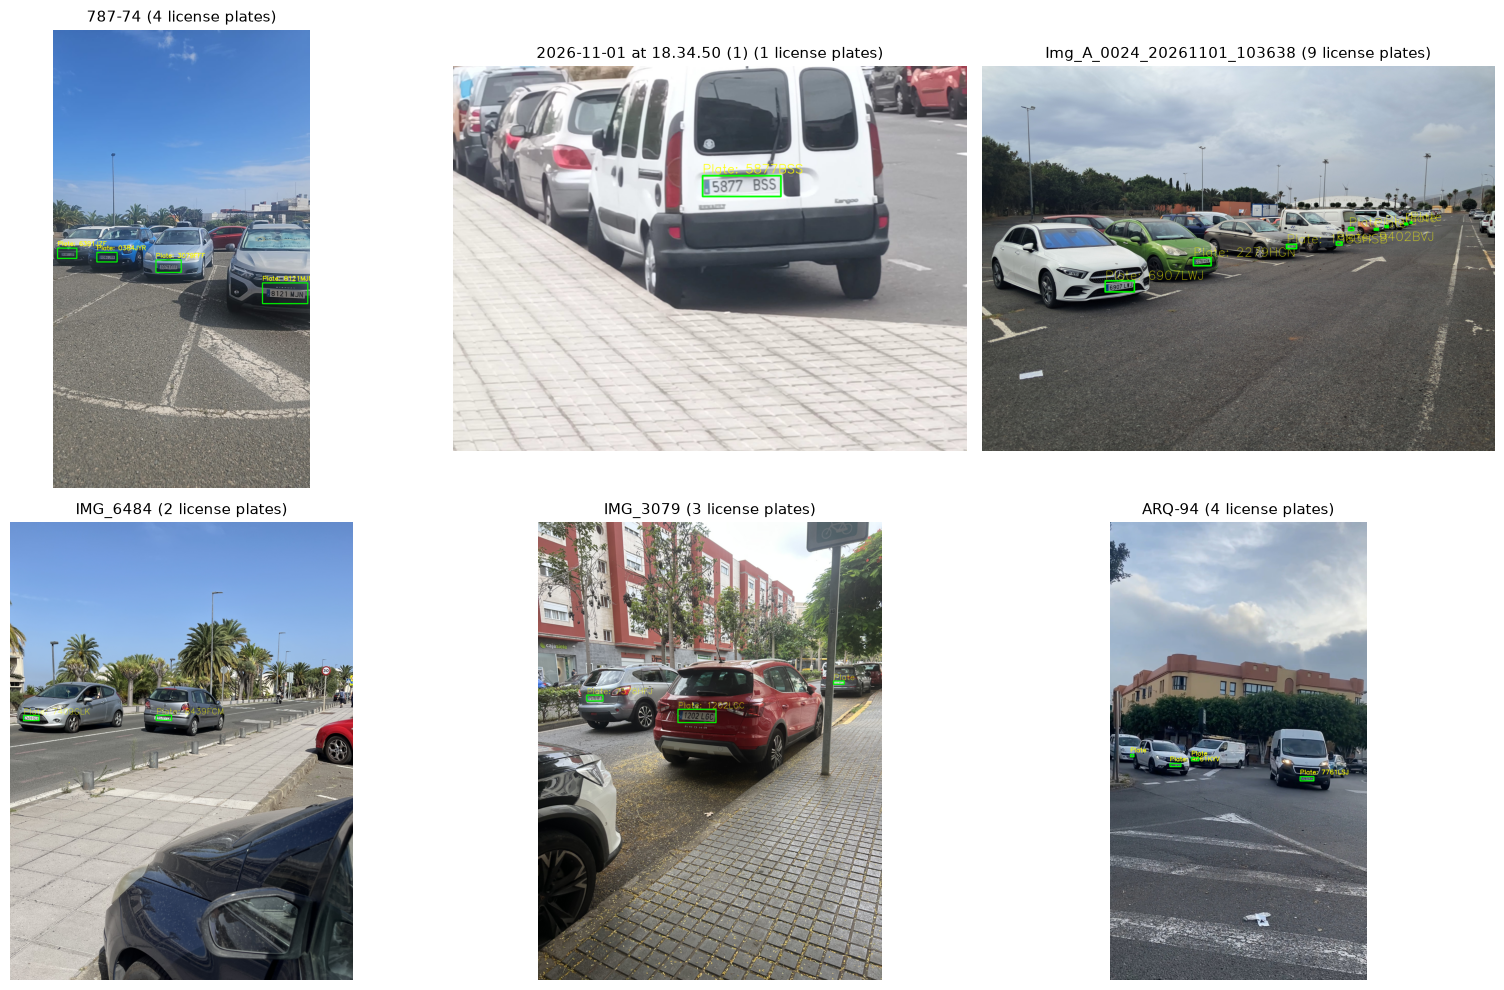

In [24]:
def visualize_dataset_samples(samples, num_samples=6, seed=SEED):
    """Show a grid of samples from a loaded dataset."""
    
    rndm_seed = get_random(seed)
    candidates = [s for s in samples if s["num_boxes"] > 0] # At least 1 plate found
    selected = rndm_seed.sample(candidates, min(num_samples, len(candidates)))

    cols = 3
    rows = (len(selected) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, sample in enumerate(selected):
        img_bgr = cv2.imread(str(sample["image_path"]))
        if img_bgr is None:
            continue
        
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]

        for box, plate in zip(sample["boxes"], sample["plates"]):
            cx, cy, bw, bh = box
            x1 = int((cx - bw / 2) * w)
            y1 = int((cy - bh / 2) * h)
            x2 = int((cx + bw / 2) * w)
            y2 = int((cy + bh / 2) * h)

            # Detection bbox in green
            cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), max(2, int(w * 0.003)))
            # Plate text
            label = f"Plate: {plate}" if plate != "None" else "Plate"
            cv2.putText(img_rgb, label, (x1, max(y1 - 10, 25)),
                        cv2.FONT_HERSHEY_SIMPLEX, max(0.6, w * 0.0008), (255, 255, 0), 2)

        axes[i].imshow(img_rgb)
        axes[i].set_title(f"{sample['stem']} ({sample['num_boxes']} license plates)", fontsize=11)
        axes[i].axis("off")

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

visualize_dataset_samples(loader.samples, num_samples=6, seed=SEED)

In [13]:
yolo_dataset_dir = (dataset_dir.absolute() / Path("yolo-training")).resolve()

dataset_yaml_path, dataset_splits = prepare_yolo_dataset(
    samples=loader.samples,
    output_dir=yolo_dataset_dir,
    split_ratios=(0.75, 0.15, 0.10),
    seed=SEED,
)

Removing old YOLO dataset dir: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset/yolo-training
 DATASET SPLIT SUMMARY
* TRAIN: 1804 images (74.98%) | 3243 license plates
* VAL  : 360 images (14.96%) | 681 license plates
* TEST : 242 images (10.06%) | 447 license plates
- File data.yaml written to: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset/yolo-training/data.yaml


# TRAINING

In [14]:
SKIP_TRAINING = True
SKIP_TESTING = True

AVAILABLE_MODELS = {
    "nano":   "yolo11n.pt",
    "small":  "yolo11s.pt",
    "medium": "yolo11m.pt",
    "large":  "yolo11l.pt",
    "xlarge": "yolo11x.pt"  
}

CHOSEN_MODEL_TYPE = "small"

model_weights = AVAILABLE_MODELS[CHOSEN_MODEL_TYPE]
print(f"Using YOLO model: [{CHOSEN_MODEL_TYPE.upper()}] with weights: {model_weights}")

model = YOLO(Path("yolo") / model_weights)
print("* Model loaded successfully.")

Using YOLO model: [SMALL] with weights: yolo11s.pt
* Model loaded successfully.


In [15]:
EPOCHS = 120
BATCH_SIZE = 16
IMGSZ = 960
PATIENCE=30

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "yolo").exists() and (NOTEBOOK_DIR / "P4" / "P4a" / "yolo").exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "P4" / "P4a"

PROJECT = (NOTEBOOK_DIR / "runs" / "detect" / "runs_plate").resolve()
EXPERIMENT_NAME = f"plate_detector_{IMGSZ}_BATCH_{BATCH_SIZE}_{CHOSEN_MODEL_TYPE}"
RUN_OUTPUT_DIR = PROJECT / EXPERIMENT_NAME

print(f"Training model on device: {device_desc}")
print(f"Epochs: {EPOCHS} | Batch Size: {BATCH_SIZE} | Image Size: {IMGSZ}x{IMGSZ}")

Training model on device: NVIDIA GPU (NVIDIA GeForce RTX 3060 Ti)
Epochs: 120 | Batch Size: 16 | Image Size: 960x960


In [ ]:
if not SKIP_TRAINING:
    train_results = model.train(
        data=str(dataset_yaml_path),
        epochs=EPOCHS,
        batch=BATCH_SIZE,
        imgsz=IMGSZ,
        device=DEVICE,
        project=str(PROJECT),
        name=EXPERIMENT_NAME,
        seed=SEED,
        patience=PATIENCE,
        amp=True if DEVICE != "mps" else False,
        rect=True, # Avoids black borders on images, but may reduce speed
        save=True,
        plots=True,
        verbose=True,
        exist_ok=True,
        workers=8,
        scale=0.5,
        hsv_v=0.4,
        hsv_s=0.6,
        mosaic=0.5,
        close_mosaic=20, # Stop mosaic augmentation last 20 epochs
        degrees=5.0,
        translate=0.1,
        box=8.5, # Box loss gain: weight of the bounding box loss
        dfl=1.5, # DFL loss gain
        cls=1.5, # Class loss gain
        freeze=0,
    )
    
    training_metrics = train_results.metrics
    print("\nTraining metrics summary:")
    for metric_name, metric_value in training_metrics.items():
        print(f" - {metric_name}: {metric_value}")

    print("\nTraning finished. Best model saved in:", train_results.best)
else:
    print("Training Skipped. Set SKIP_TRAINING = False to enable training.")

Training Skipped. Set SKIP_TRAINING = False to enable training.


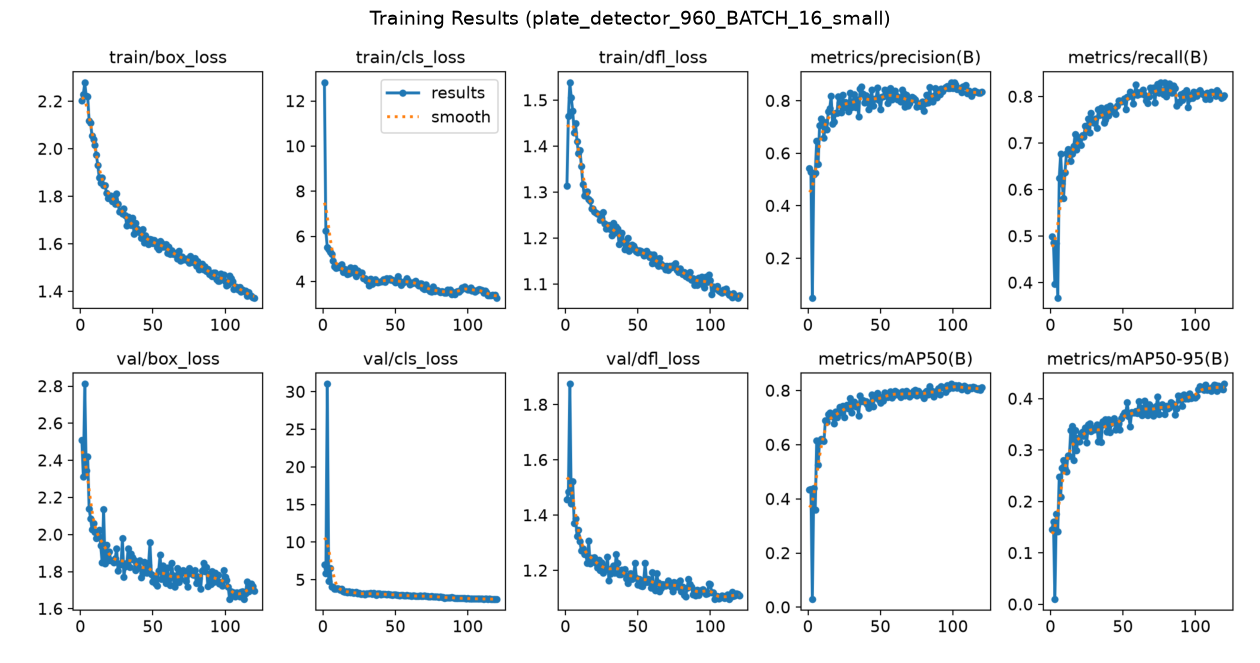

In [12]:
results_img_path = RUN_OUTPUT_DIR / "results.png"
if results_img_path.exists():
    plt.figure(figsize=(16, 10))
    res_img = cv2.imread(str(results_img_path))
    res_img = cv2.cvtColor(res_img, cv2.COLOR_BGR2RGB)
    plt.imshow(res_img)
    plt.axis("off")
    plt.title(f"Training Results ({EXPERIMENT_NAME})", fontsize=14)
    plt.show()
else:
    print(f"No results image found: {results_img_path}")

# TESTING

- **Precision (P)**: Proporción de matrículas predichas que son correctas.
- **Recall (R)**: Proporción de matrículas reales detectadas por el modelo.
- **mAP@50**: Precisión media calculada con umbral IoU de $0.50$.
- **mAP@50-95**: Precisión media acumulada calculada para umbrales IoU entre $0.50$ y $0.95$ con paso $0.05$.

In [16]:
best_weights_path = RUN_OUTPUT_DIR / "weights" / "best.pt"
if not best_weights_path.exists():
    print(f"WARNING: no model found at {best_weights_path}, using the model in memory instead.")
    trained_model = model
else:
    print(f"Loading best weights from: {best_weights_path}")
    trained_model = YOLO(str(best_weights_path))

Loading best weights from: /home/skinnydevi/Development/computer-vision/P4/P4a/runs/detect/runs_plate/plate_detector_960_BATCH_16_small/weights/best.pt


In [14]:
if SKIP_TESTING:
    print("Testing skipped. Set RUN_TESTING = True to enable evaluation on the test set.")
else:
    print("Evaluating on the TEST set...")
    test_results = trained_model.val(
        data=str(dataset_yaml_path),
        split="test",
        device=DEVICE,
        project=str(RUN_OUTPUT_DIR),
        name="val",
        plots=True,
        iou=0.55, # prevent duplicate detections for small objects
    )
    
    precision = test_results.box.p[0] if len(test_results.box.p) > 0 else 0.0
    recall = test_results.box.r[0] if len(test_results.box.r) > 0 else 0.0
    map50 = test_results.box.map50
    map50_95 = test_results.box.map

    print("=" * 60)
    print(" DETECTION METRICS ON TEST SET")
    print("=" * 60)
    print(f"• Precision (P):       {precision:.4f} ({precision * 100:.2f}%)")
    print(f"• Recall (R):          {recall:.4f} ({recall * 100:.2f}%)")
    print(f"• mAP@50:              {map50:.4f} ({map50 * 100:.2f}%)")
    print(f"• mAP@50-95:           {map50_95:.4f} ({map50_95 * 100:.2f}%)")
    print("=" * 60)


Testing skipped. Set RUN_TESTING = True to enable evaluation on the test set.


 LABEL SUMMARY 
* Detected: number of detections made by model in the image
* Total: number of bboxes in the dataset loader for the image (excluding any invalid or filtered annotations)
* Real: number of bboxes in the original annotation file for the image (including any invalid, noise or filtered annotations)


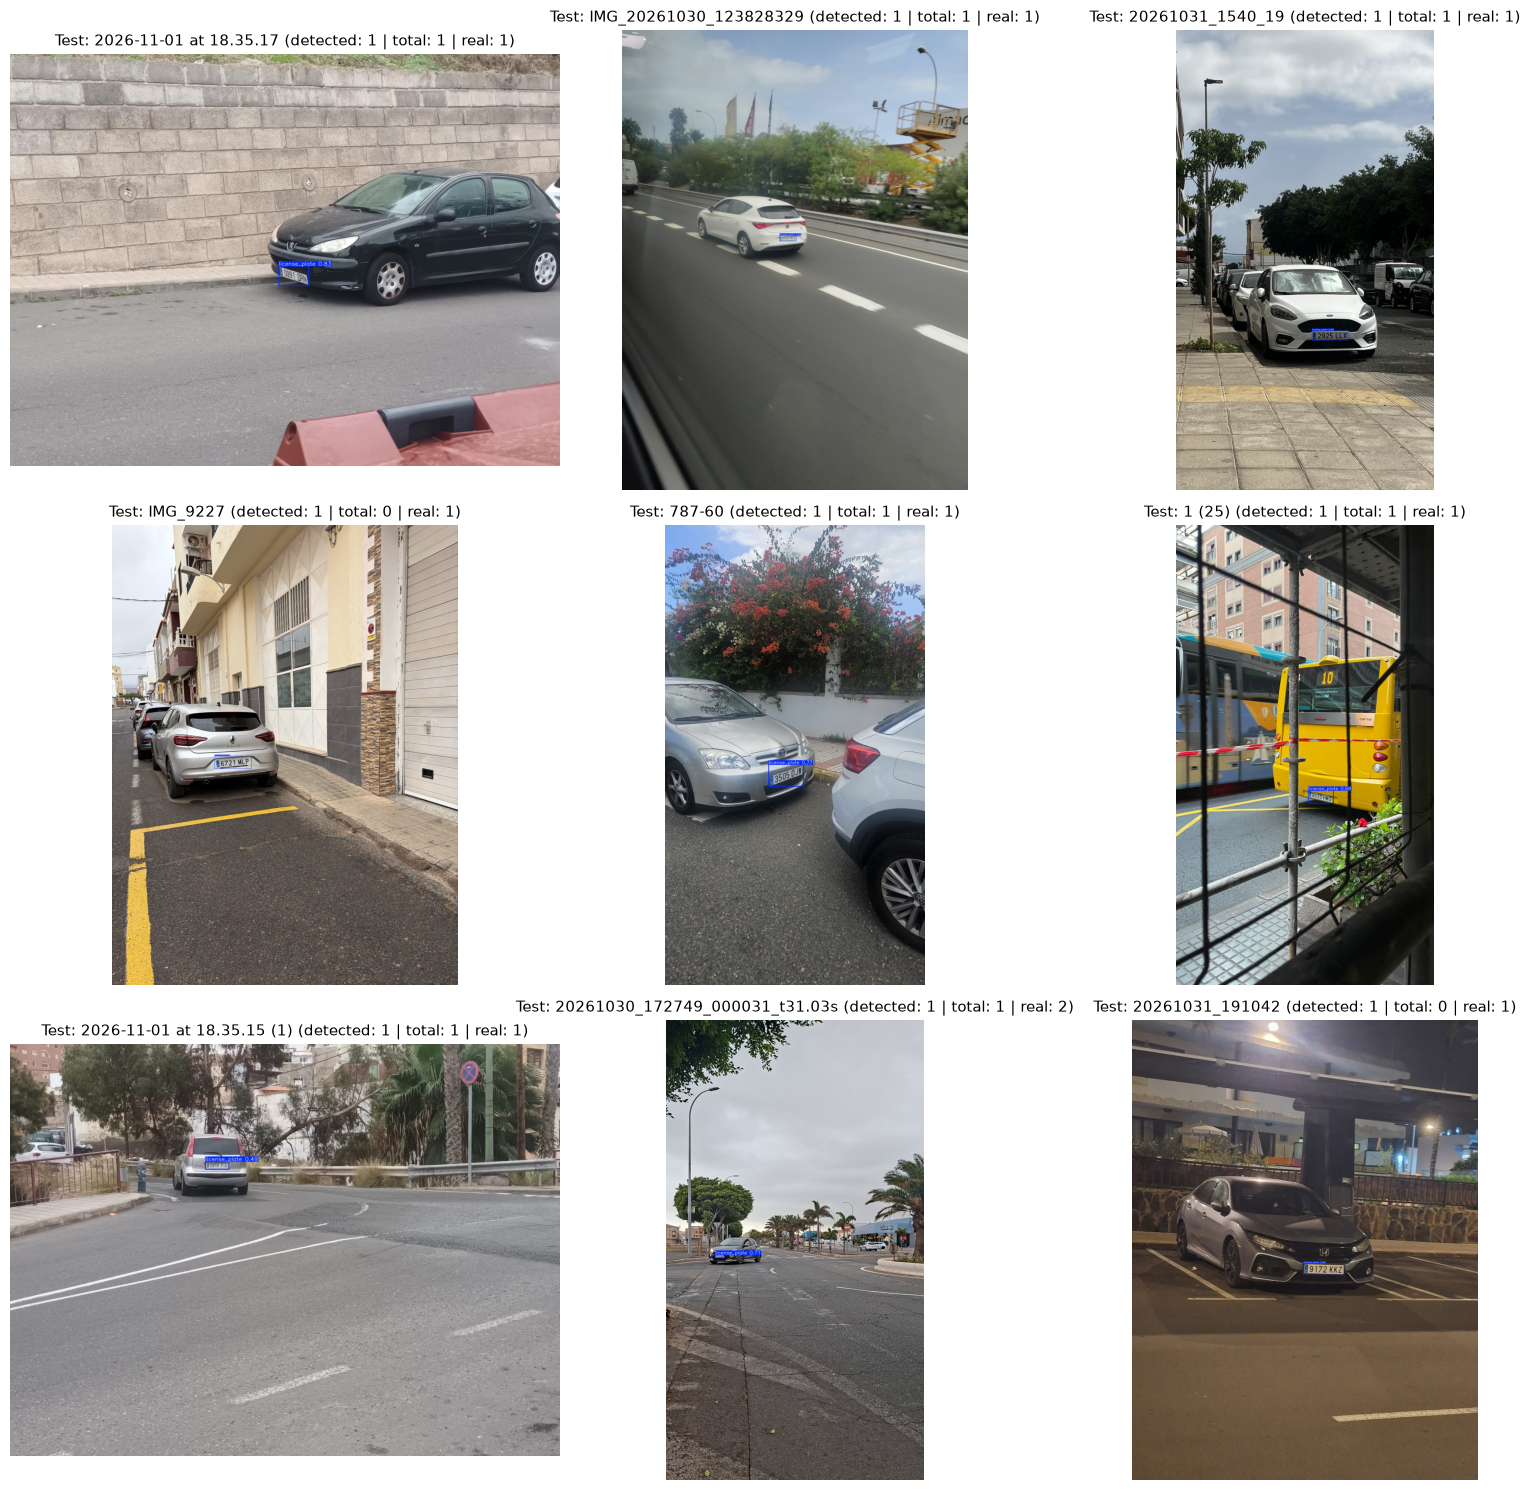

In [17]:
def get_sample_annotation_count(sample):
    """
    Get the numberif available of original bounding boxes for a given sample.
    This function checks for the existence of an annotation file and counts the boxes.
    """
    ann_path = sample.get("annotation_path")
    if ann_path and Path(ann_path).exists():
        try:
            with open(ann_path, "r", encoding="utf-8") as f:
                ann_data = json.load(f)
            
            sample_original_total_boxes = len(ann_data) if isinstance(ann_data, list) else len(sample.get("boxes", []))
        except Exception:
            sample_original_total_boxes = len(sample.get("boxes", []))
    else:
        sample_original_total_boxes = sample.get("num_boxes", len(sample.get("boxes", [])))
    
    return sample_original_total_boxes

def visualize_test_predictions(trained_model, test_samples, num_samples=6, conf_threshold=0.35, seed=SEED):
    """
    Display predictions from the trained model on a random selection of test samples.
    """
    
    rndm_seed = get_random(seed)
    selected = rndm_seed.sample(test_samples, min(num_samples, len(test_samples)))

    cols = 3
    rows = (len(selected) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, sample in enumerate(selected):
        img_path = sample["image_path"]
        results = trained_model.predict(source=str(img_path), conf=conf_threshold, verbose=False)
        
        annotated_bgr = results[0].plot(line_width=2, font_size=1)
        annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)

        num_det = len(results[0].boxes)
        loader_stored_detections = loader.get_annotation_count(img_path)
        real_annotation_count = get_sample_annotation_count(sample)
        
        axes[i].imshow(annotated_rgb)
        axes[i].set_title(f"Test: {sample['stem']} (detected: {num_det} | total: {loader_stored_detections} | real: {real_annotation_count})", fontsize=11)
        axes[i].axis("off")

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

rng_seed = random.Random()
rndm_seed = rng_seed.randint(0, 999999)
print(" LABEL SUMMARY ")
print("* Detected: number of detections made by model in the image")
print("* Total: number of bboxes in the dataset loader for the image (excluding any invalid or filtered annotations)")
print("* Real: number of bboxes in the original annotation file for the image (including any invalid, noise or filtered annotations)")
visualize_test_predictions(trained_model, dataset_splits["test"], num_samples=9, conf_threshold=0.4, seed=SEED)

# TESTING WITH VIDEO

In [16]:
YOLO_TRACKER_CONFIG = {
    "tracker_type": "botsort", # Used for tracking license plates across frames
    "fuse_score": True, # Fuse: Use detection confidence score to improve tracking
    "gmc_method": "sparseOptFlow", # Use sparse optical flow for motion compensation
    "with_reid": False, # REID: Use appearance features for re-identification (slower, but more robust)
    "appearance_thresh": 0.7, # Appearance similarity threshold for re-identification
    "match_thresh": 0.75, # Matching threshold for associating detections to existing tracks
    "new_track_thresh": 0.25, # Confidence threshold for creating new tracks
    "proximity_thresh": 0.5, # Proximity threshold for associating detections to existing tracks
    "track_high_thresh": 0.25, # Confidence threshold for keeping tracks alive
    "track_low_thresh": 0.1, # Confidence threshold for terminating tracks
    "track_buffer": 90, # Number of frames to keep a track alive without detections
}
YOLO_TRACKER_CONFIG_PATH = Path("yolo_tracker_file.yaml").resolve()

with open(YOLO_TRACKER_CONFIG_PATH, "w") as tracker_file:
    yaml.dump(YOLO_TRACKER_CONFIG, tracker_file, default_flow_style=False)

In [ ]:
class PedestrianOcclusionManager:
    """
    Manages the continuity of pedestrian identities when they suffer occlusions
    (e.g., when a vehicle passes in front of a person).
    """

    def __init__(self, max_gap_frames=90, max_distance=220, min_similarity=0.60):
        self.max_gap_frames = max_gap_frames
        self.max_distance = max_distance
        self.min_similarity = min_similarity
        
        self.id_remap = {}       # raw_yolo_id -> canonical_id
        self.lost_tracks = {}    # canonical_id -> dict with info of last known state
        self.active_tracks = {}  # canonical_id -> dict with last box and color histogram

    def resolve_id(self, raw_id):
        """
        Resolve a raw ID to its canonical ID.
        """
                
        curr = raw_id
        visited = set()
        while curr in self.id_remap and curr not in visited:
            visited.add(curr)
            curr = self.id_remap[curr]
        
        return curr

    @staticmethod
    def extract_color_hist(frame, box):
        """
        Extract a color histogram from a region of interest in the frame.
        """
                
        x1, y1, x2, y2 = box
        crop = frame[max(0, y1):max(0, y2), max(0, x1):max(0, x2)]
        if crop.size == 0 or crop.shape[0] < 6 or crop.shape[1] < 6:
            return None
        
        hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
        hist = cv2.calcHist([hsv], [0, 1], None, [16, 16], [0, 180, 0, 256])
        cv2.normalize(hist, hist, 0, 1, cv2.NORM_MINMAX)
        return hist

    @staticmethod
    def get_center(box):
        return ((box[0] + box[2]) / 2.0, (box[1] + box[3]) / 2.0)

    @staticmethod
    def compute_distance(p1, p2):
        """Euclidean distance between two points p1 and p2, where each point is (x, y)"""
        return ((p1[0] - p2[0]) ** 2 + (p1[1] - p2[1]) ** 2) ** 0.5

    def _is_track_known(self, raw_id, canonical_id):
        return raw_id in self.id_remap or canonical_id in self.active_tracks

    def _check_lost_tracks(self, current_frame, p_center, p_hist):
        # If it's a new track we don't know created by YOLO
        best_match_id = None
        best_score = -1.0
        
        for lost_id, lost_info in list(self.lost_tracks.items()):
            # Check if the lost track is too old
            gap = current_frame - lost_info["last_frame"]
            if gap > self.max_gap_frames:
                continue
            
            # Check distance between last known position and current detection
            lost_center = self.get_center(lost_info["last_box"])
            dist = self.compute_distance(p_center, lost_center)
            max_allowed_dist = min(self.max_distance, 40.0 + gap * 3.5)
            if dist > max_allowed_dist:
                continue
            
            # HSV color histogram similarity (0.0 to 1.0, higher is more similar)
            similarity = 0.5
            if p_hist is not None and lost_info["color_hist"] is not None:
                similarity = cv2.compareHist(
                    p_hist, lost_info["color_hist"], cv2.HISTCMP_CORREL
                )
            
            # If the lost track was occluded by a vehicle and reappears nearby, 
            # or if the similarity is high
            # 1200 = max distance in pixels for normalization
            score = similarity - (dist / 1200.0)
            if (similarity >= self.min_similarity) or (
                lost_info["occluded_by_vehicle"]
                and dist < 90
                and similarity > 0.35
            ):
                if score > best_score:
                    best_score = score
                    best_match_id = lost_id
        
        return best_match_id, best_score

    def _relink_track(self, raw_id, best_match_id):
        self.id_remap[raw_id] = best_match_id
        if best_match_id in self.lost_tracks:
            del self.lost_tracks[best_match_id]
    
    def _update_active_track(self, canonical_id, p_box, p_hist, current_frame):
        self.active_tracks[canonical_id] = {
            "last_frame": current_frame,
            "last_box": p_box,
            "color_hist": (
                p_hist
                if p_hist is not None
                else self.active_tracks.get(canonical_id, {}).get("color_hist")
            ),
        }
    
    def _process_yolo_tracks(self, people, frame, current_frame):
        current_canonical_ids = set()
        
        for person in people:
            raw_id = person["track_id"]
            if raw_id == "" or raw_id is None:
                continue

            canonical_id = self.resolve_id(raw_id)
            p_box = person["box"]
            p_center = self.get_center(p_box)
            p_hist = self.extract_color_hist(frame, p_box)
            
            if self._is_track_known(raw_id, canonical_id):
                continue  # Already known track, no need to check lost tracks
            
            # Check lost tracks for potential matches
            best_match_id, _ = self._check_lost_tracks(current_frame, p_center, p_hist)
            
            if best_match_id is not None:
                # Re-link track: assign original ID
                canonical_id = best_match_id
                self._relink_track(raw_id, best_match_id)
                
            person["track_id"] = canonical_id
            current_canonical_ids.add(canonical_id)

            # Update active tracks with the latest information
            self._update_active_track(canonical_id, p_box, p_hist, current_frame)
        
        return current_canonical_ids
    
    def _process_missing_people_in_frame(self, current_canonical_ids, vehicle_boxes):
        disappeared_ids = set(self.active_tracks.keys()) - current_canonical_ids
        for dis_id in disappeared_ids:
            dis_info = self.active_tracks[dis_id]
            dis_box = dis_info["last_box"]
            dis_center = self.get_center(dis_box)

            # Comprobar si desapareció solapado con un vehículo
            was_occluded = False
            for vx1, vy1, vx2, vy2 in vehicle_boxes:
                if (vx1 <= dis_center[0] <= vx2 and vy1 <= dis_center[1] <= vy2) or (
                    max(dis_box[0], vx1) < min(dis_box[2], vx2)
                    and max(dis_box[1], vy1) < min(dis_box[3], vy2)
                ):
                    was_occluded = True
                    break

            self.lost_tracks[dis_id] = {
                "last_frame": dis_info["last_frame"],
                "last_box": dis_box,
                "color_hist": dis_info["color_hist"],
                "occluded_by_vehicle": was_occluded,
            }
            del self.active_tracks[dis_id]
    
    def _cleanup_old_lost_tracks(self, current_frame):
        for lost_id in list(self.lost_tracks.keys()):
            if current_frame - self.lost_tracks[lost_id]["last_frame"] > self.max_gap_frames:
                del self.lost_tracks[lost_id]

    def process_people_in_frame(self, frame, people, current_frame, vehicle_boxes):
        """
        Process the people in the current frame, resolving ID switches due to occlusion.
        """
        
        # Process YOLO trackers and update active tracks
        current_canonical_ids = self._process_yolo_tracks(people, frame, current_frame)

        # Identify which pedestrians disappeared in this frame
        self._process_missing_people_in_frame(current_canonical_ids, vehicle_boxes)
        
        # Clean up lost tracks that have exceeded the maximum gap frames
        self._cleanup_old_lost_tracks(current_frame)

In [ ]:
class LicensePlateVideoProcessor:
    """
    Processes a video to detect and track vehicles, license plates and pedestrians.
    Applies occlusion management, hierarchical license plate memory and track class consensus.
    Saves the annotated video and generates the results CSV.
    """
    
    def __init__(
        self, 
        vehicle_model, 
        plate_model, 
        tracker_config=YOLO_TRACKER_CONFIG_PATH, 
        max_gap_frames=90, 
        max_distance=220,
        apply_censoring=False
    ):
        self.vehicle_model: YOLO = vehicle_model
        self.plate_model: YOLO = plate_model
        self.tracker_config = tracker_config
        self.occlusion_manager = PedestrianOcclusionManager(
            max_gap_frames=max_gap_frames, 
            max_distance=max_distance
        )
        self.apply_censoring = apply_censoring
        
        self.video_width = None
        self.video_height = None
        self.video_fps = None
        self.video_total_frames = None
        
        self.vehicle_classes = {
            0: "person",
            2: "car",
            3: "motorbike",
            5: "bus",
            # 7: "truck",
        }
        
        self.csv_columns = [
            "fotograma",
            "tipo_objeto",
            "confianza",
            "identificador_tracking",
            "x1",
            "y1",
            "x2",
            "y2",
            "matrícula_en_su_caso",
            "confianza",
            "mx1",
            "my1",
            "mx2",
            "my2",
            "texto_matricula",
        ]
        
        # Store the history of detected classes for each track ID
        self.track_class_history = defaultdict(lambda: Counter())
        self.confirmed_plates = set()
        self.raw_detection_counts = {name: 0 for name in self.vehicle_classes.values()}
        self.raw_detection_counts["license_plate"] = 0
        
    def box_values(self, box):
        """
        Get the bounding box coordinates, confidence and track ID from a YOLO box object.
        """
        
        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].tolist()]
        confidence = float(box.conf[0])
        track_id = int(box.id[0]) if box.id is not None else ""
        
        return x1, y1, x2, y2, confidence, track_id
    
    def plate_belongs_to_vehicle(self, plate_box, vehicle_box):
        """
        Determine if a detected license plate belongs to a detected vehicle based on bounding box overlap and position.
        """
        
        px1, py1, px2, py2 = plate_box
        vx1, vy1, vx2, vy2 = vehicle_box

        # Test if center of plate is inside vehicle box
        pcx = (px1 + px2) / 2.0
        pcy = (py1 + py2) / 2.0
        if vx1 <= pcx <= vx2 and vy1 <= pcy <= vy2:
            return True

        # Check if the intersection of the two boxes is at least 50% of the plate area
        ix1 = max(px1, vx1)
        iy1 = max(py1, vy1)
        ix2 = min(px2, vx2)
        iy2 = min(py2, vy2)
        if ix1 < ix2 and iy1 < iy2:
            inter_area = (ix2 - ix1) * (iy2 - iy1)
            plate_area = max(1, (px2 - px1) * (py2 - py1))
            if (inter_area / plate_area) >= 0.5:
                return True

        return False
    
    def _prepare_video_writer(self, input_video_path, output_video_path, max_frames=None):
        video_capture = cv2.VideoCapture(str(input_video_path))
        if not video_capture.isOpened():
            raise RuntimeError(f"Could not open video: {input_video_path}")
    
        self.video_width = int(video_capture.get(cv2.CAP_PROP_FRAME_WIDTH))
        self.video_height = int(video_capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
        self.video_fps = video_capture.get(cv2.CAP_PROP_FPS) or 25.0
        self.video_total_frames = int(video_capture.get(cv2.CAP_PROP_FRAME_COUNT))
    
        if max_frames is not None:
            self.video_total_frames = min(self.video_total_frames, max_frames)
    
        writer = cv2.VideoWriter(
            str(output_video_path),
            cv2.VideoWriter_fourcc(*"mp4v"),
            self.video_fps,
            (self.video_width, self.video_height),
        )
        
        return video_capture, writer
    
    def _detect_vehicles(self, frame, conf_threshold):
        return self.vehicle_model.track(
            frame,
            classes=list(self.vehicle_classes.keys()),
            conf=conf_threshold,
            persist=True,
            tracker=self.tracker_config,
            verbose=False,
        )
    
    def _detect_license_plates(self, frame, conf_threshold):
        return self.plate_model(
            frame,
            conf=conf_threshold,
            verbose=False,
        )
    
    def _classify_detections(self, vehicle_results):
        current_vehicles = []
        current_people = []
        vehicle_boxes = []
        if not vehicle_results or len(vehicle_results[0].boxes) == 0:
            return current_vehicles, current_people, vehicle_boxes
        
        for box in vehicle_results[0].boxes:
            x1, y1, x2, y2, conf, track_id = self.box_values(box)
            cls_id = int(box.cls[0])
            
            # Map the YOLO class ID to a human-readable type
            raw_type = self.vehicle_classes.get(cls_id)
            if raw_type is None:
                continue
            
            # Update raw class count
            self.raw_detection_counts[raw_type] += 1
            item = {
                "type": raw_type,
                "confidence": conf,
                "track_id": track_id,
                "box": (x1, y1, x2, y2),
            }
            
            if raw_type == "person":
                current_people.append(item)
            else:
                current_vehicles.append(item)
                vehicle_boxes.append((x1, y1, x2, y2))
                
        return current_vehicles, current_people, vehicle_boxes
    
    def _update_track_class_history(self, tracks: list):
        for track in tracks:
            tid = track["track_id"]
            if tid == "":
                continue
            
            self.track_class_history[tid][track["type"]] += 1
            # Use mode (moda) to determine the dominant class for this track
            dominant_type = self.track_class_history[tid].most_common(1)[0][0]
            track["type"] = dominant_type
            
    def _process_license_plates(self, plate_results, current_vehicles):
        current_plates = []
        if plate_results is None or len(plate_results) == 0:
            return current_plates
        
        # Process each detected license plate and associate it with a vehicle if possible
        for box in plate_results[0].boxes:
            px1, py1, px2, py2 = [int(v) for v in box.xyxy[0].tolist()]
            plate_conf = float(box.conf[0])
            
            current_plates.append({
                "box": (px1, py1, px2, py2),
                "confidence": plate_conf,
                "associated": False,
            })
            
            self.raw_detection_counts["license_plate"] += 1
        
        for plate in current_plates:
            matched_vehicle = None
            for vehicle in current_vehicles:
                if self.plate_belongs_to_vehicle(plate["box"], vehicle["box"]):
                    matched_vehicle = vehicle
                    break
                
            if matched_vehicle is not None:
                plate["associated"] = True
                plate["vehicle_id"] = matched_vehicle["track_id"]
                if matched_vehicle["track_id"] != "":
                    self.confirmed_plates.add(matched_vehicle["track_id"])
            else:
                plate["vehicle_id"] = ""
        
        return current_plates
    
    def _write_vehicles_in_csv(self, csv_writer, annotated_frame, frame_number, current_vehicles, current_plates):
        for vehicle in current_vehicles:
            # Get bbox
            vx1, vy1, vx2, vy2 = vehicle["box"]
            v_id = vehicle["track_id"]
            
            # Did we find a license plate in this frame for this vehicle?
            plate_in_this_frame = next(
                (plate for plate in current_plates if plate["associated"] and self.plate_belongs_to_vehicle(plate["box"], vehicle["box"])),
                None
            )
            
            if plate_in_this_frame is not None:
                px1, py1, px2, py2 = plate_in_this_frame["box"]
                csv_writer.writerow([
                    frame_number,
                    vehicle["type"],
                    f"{vehicle['confidence']:.4f}",
                    v_id,
                    vx1, vy1, vx2, vy2,
                    "yes",
                    f"{plate_in_this_frame['confidence']:.4f}",
                    px1, py1, px2, py2,
                    f"{vehicle['type']}_{vehicle['track_id']}_plate",
                ])
            else:
                csv_writer.writerow([
                    frame_number,
                    vehicle["type"],
                    f"{vehicle['confidence']:.4f}",
                    v_id,
                    vx1, vy1, vx2, vy2,
                    "no",
                    "",
                    "",
                    "",
                    "",
                    "",
                    "",
                ])
                
            # Draw vehicle bounding box in CYAN
            cv2.rectangle(annotated_frame, (vx1, vy1), (vx2, vy2), (255, 120, 0), 2)
            v_label = f"{vehicle['type']} ID:{v_id} {vehicle['confidence']:.2f}"
            cv2.putText(
                annotated_frame,
                v_label,
                (vx1, max(vy1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 140, 0),
                2,
            )
    
    def _write_people_to_csv(self, csv_writer, annotated_frame, frame_number, current_people):
        for person in current_people:
            px1, py1, px2, py2 = person["box"]
            p_id = person["track_id"]
            
            csv_writer.writerow([
                frame_number,
                person["type"],
                f"{person['confidence']:.4f}",
                p_id,
                px1, py1, px2, py2,
                "no",
                "",
                "",
                "",
                "",
                "",
                "",
            ])
            
            # Draw person bounding box in ORANGE
            cv2.rectangle(annotated_frame, (px1, py1), (px2, py2), (0, 165, 255), 2)
            p_label = f"{person['type']} ID:{p_id} {person['confidence']:.2f}"
            cv2.putText(
                annotated_frame,
                p_label,
                (px1, max(py1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 165, 255),
                2,
            )
        
    def _write_plates_to_csv(self, csv_writer, annotated_frame, frame_number, current_plates):
        for plate in current_plates:
            px1, py1, px2, py2 = plate["box"]
            
            # Write orphan license plates
            if not plate["associated"]:
                csv_writer.writerow([
                    frame_number,
                    "license_plate",
                    f"{plate['confidence']:.4f}",
                    "",
                    px1, py1, px2, py2,
                    "yes",
                    f"{plate['confidence']:.4f}",
                    px1, py1, px2, py2,
                    "orphan_plate",
                ])
            
            # Draw license plate bounding box in GREEN
            cv2.rectangle(annotated_frame, (px1, py1), (px2, py2), (0, 255, 0), 2)
            plate_label = f"MATRICULA {plate['confidence']:.2f}".strip()
            cv2.putText(
                annotated_frame,
                plate_label,
                (px1, max(py1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 0),
                2,
            )
    
    def _write_frame_and_csv(self, frame, frame_number, csv_writer, current_vehicles, current_people, current_plates):
        annotated_frame = frame.copy()
        
        self._write_vehicles_in_csv(csv_writer, annotated_frame, frame_number, current_vehicles, current_plates)
        self._write_people_to_csv(csv_writer, annotated_frame, frame_number, current_people)
        self._write_plates_to_csv(csv_writer, annotated_frame, frame_number, current_plates)
        
        return annotated_frame
    
    def _create_hud_overlay(self, annotated_frame, frame_number, min_frames_to_confirm: int):
        hud_overlay = annotated_frame.copy()
        cv2.rectangle(hud_overlay, (0, 0), (self.video_width, 40), (25, 25, 25), -1)
        cv2.addWeighted(hud_overlay, 0.65, annotated_frame, 0.35, 0, annotated_frame)
        
        # Get classes for HUD
        hud_confirmed = defaultdict(int)
        for tid, hist in self.track_class_history.items():
            if sum(hist.values()) >= min_frames_to_confirm:
                dom_cls = hist.most_common(1)[0][0]
                hud_confirmed[dom_cls] += 1
                
        hud_text = (
            f"Fotograma: {frame_number}/{self.video_total_frames} | "
            f"Personas: {hud_confirmed['person']} | "
            f"Coches: {hud_confirmed['car']} | "
            f"Motos: {hud_confirmed['motorbike']} | "
            f"Autobuses: {hud_confirmed['bus']} | "
            # f"Camiones: {hud_confirmed['truck']} | "
            f"Matrículas: {len(self.confirmed_plates)}"
        )
        cv2.putText(
            annotated_frame,
            hud_text,
            (12, 26),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (255, 255, 255),
            2,
        )
    
    def _apply_people_censor(self, annotated_frame, current_people):
        if not self.apply_censoring:
            return
        
        for person in current_people:
            px1, py1, px2, py2 = person["box"]
            
            # Apply blur to a person's bbox upper half
            censor_area = (px1, py1, px2, py1 + (py2 - py1) // 4)
            censor_crop = annotated_frame[censor_area[1]:censor_area[3], censor_area[0]:censor_area[2]]
            if censor_crop.size > 0:
                blurred_crop = cv2.GaussianBlur(censor_crop, (25, 25), 30)
                annotated_frame[censor_area[1]:censor_area[3], censor_area[0]:censor_area[2]] = blurred_crop
    
    def _apply_incoming_car_censor(self, annotated_frame, current_vehicles):
        if not self.apply_censoring:
            return
        
        for vehicle in current_vehicles:
            if vehicle["confidence"] < 0.65:
                continue
            
            vx1, vy1, vx2, vy2 = vehicle["box"]
            # Apply blur to the car's bounding box
            censor_area = (vx1, vy1, vx2, vy1 + (vy2 - vy1) // 3)
            censor_crop = annotated_frame[censor_area[1]:censor_area[3], censor_area[0]:censor_area[2]]
            if censor_crop.size > 0:
                blurred_crop = cv2.GaussianBlur(censor_crop, (25, 25), 30)
                annotated_frame[censor_area[1]:censor_area[3], censor_area[0]:censor_area[2]] = blurred_crop
                
    def _process_video_frame(self, frame, csv_writer, frame_number: int, conf_threshold: float):
        # 1 - Process vehicle detection and tracking
        vehicle_results = self._detect_vehicles(frame, conf_threshold)
        
        # 2 - Process license plate detection and tracking
        plate_results = self._detect_license_plates(frame, conf_threshold)
        
        # 3 - Process license plate detection and tracking
        current_vehicles, current_people, vehicle_boxes = self._classify_detections(vehicle_results)
        
        # 4 - Process pedestrian occlusion management
        self.occlusion_manager.process_people_in_frame(frame, current_people, frame_number, vehicle_boxes)
        
        # 5 - Update class history and assign dominant class for each track
        self._update_track_class_history(current_vehicles + current_people)
        
        # 6 - Process license plate readings
        current_plates = self._process_license_plates(plate_results, current_vehicles)
        
        # 7 - Write annotated frame to video and CSV
        annotated_frame = self._write_frame_and_csv(frame, frame_number, csv_writer, current_vehicles, current_people, current_plates)
        
        # 8 - Apply optional face censoring
        self._apply_incoming_car_censor(annotated_frame, current_vehicles)
        self._apply_people_censor(annotated_frame, current_people)
        
        return annotated_frame
        
    def print_summary(self, output_video_path, output_csv_path, min_frames_to_confirm):
        confirmed_unique_objects = {name: set() for name in self.vehicle_classes.values()}
        # Count unique confirmed objects based on track class history
        for tid, hist in self.track_class_history.items():
            if sum(hist.values()) >= min_frames_to_confirm:
                dom_cls = hist.most_common(1)[0][0]
                if dom_cls in confirmed_unique_objects:
                    confirmed_unique_objects[dom_cls].add(tid)
    
        unique_counts = {
            cls_name: len(confirmed_unique_objects[cls_name])
            for cls_name in self.vehicle_classes.values()
        }
        unique_counts["license_plate"] = len(self.confirmed_plates)
    
        print("\n" + "=" * 60)
        print(" VIDEO PROCESSING SUMMARY")
        print("=" * 60)
        print(f"* Video output path: {output_video_path}")
        print(f"* Results CSV path:   {output_csv_path}")
        print("\n" + "-" * 60)
        print(" TOTAL COUNT OF CONFIRMED UNIQUE OBJECTS:")
        print("-" * 60)
        for obj_type, count in unique_counts.items():
            print(f"  * {obj_type:15s}: {count}")
        print("-" * 60)
        print(" RAW DETECTIONS PER FRAME:")
        for obj_type, count in self.raw_detection_counts.items():
            print(f"  * {obj_type:15s}: {count} total detections")
        print("=" * 60)
        
        return unique_counts, self.raw_detection_counts
    
    def process_video(
        self,
        input_video_path: Path | str,
        output_video_path: Path | str,
        output_csv_path: Path | str,
        conf_threshold=0.35,
        show_window=False,
        max_frames=None | int,
        min_frames_to_confirm=5,
    ):
        """
        Args:
            input_video_path (str or Path): Path to the input video file.
            output_video_path (str or Path): Path to save the annotated output video.
            output_csv_path (str or Path): Path to save the results CSV file.
            conf_threshold (float): Confidence threshold for detections (default: 0.35).
            show_window (bool): Whether to display the annotated video in a window (default: False).
            max_frames (int or None): Maximum number of frames to process (default: None, process all frames).
            min_frames_to_confirm (int): Minimum number of frames required to confirm an object's class (default: 5).
        """
        
        video_capture, video_writer = self._prepare_video_writer(input_video_path, output_video_path, max_frames)
        
        with open(output_csv_path, "w", newline="", encoding="utf-8") as csv_file:
            csv_writer = csv.writer(csv_file)
            csv_writer.writerow(self.csv_columns)
            
            frame_number = 0
            while video_capture.isOpened():
                ret, frame = video_capture.read()
                if not ret or (max_frames is not None and frame_number >= max_frames):
                    break
                
                frame_number += 1
                if frame_number % 10 == 0 or frame_number == 1:
                    print("Processing frame:", frame_number, "/", self.video_total_frames, end="\r")
                
                annotated_frame = self._process_video_frame(frame, csv_writer, frame_number, conf_threshold)
                self._create_hud_overlay(annotated_frame, frame_number, min_frames_to_confirm)
                
                video_writer.write(annotated_frame)
                if show_window:
                    cv2.imshow("Annotated Video", annotated_frame)
                    if cv2.waitKey(1) == 27: # ESC key to exit
                        break
        
        video_capture.release()
        video_writer.release()
        if show_window:
            cv2.destroyAllWindows()
        print("\nProcessing finished.")

In [ ]:
VIDEO_INPUT_PATH = Path("plate_test_video.mp4").resolve()
VIDEO_OUTPUT_PATH = Path("results/yolo_dual_detections.mp4").resolve()
CSV_OUTPUT_PATH = Path("results/yolo_dual_detections.csv").resolve()
FRAMES_TO_CONFIRM_CLASS = 5
CONFIDENCE_THRESHOLD = 0.35
APPLY_CENSORING = True
COMPRESS_VIDEO = True

In [ ]:
standard_yolo_model = YOLO(Path("yolo") / "yolo11n.pt")
plate_processor = LicensePlateVideoProcessor(
    vehicle_model=standard_yolo_model,
    plate_model=trained_model,
    tracker_config=YOLO_TRACKER_CONFIG_PATH,
    max_gap_frames=90,
    max_distance=220,
    apply_censoring=APPLY_CENSORING
)

plate_processor.process_video(
    input_video_path=VIDEO_INPUT_PATH,
    output_video_path=VIDEO_OUTPUT_PATH,
    output_csv_path=CSV_OUTPUT_PATH,
    conf_threshold=CONFIDENCE_THRESHOLD,
    show_window=True,
    max_frames=None,
    min_frames_to_confirm=FRAMES_TO_CONFIRM_CLASS
)

plate_processor.print_summary(
    output_video_path=VIDEO_OUTPUT_PATH,
    output_csv_path=CSV_OUTPUT_PATH,
    min_frames_to_confirm=FRAMES_TO_CONFIRM_CLASS
)

Processing frame: 2830 / 2832
 VIDEO PROCESSING SUMMARY
* Video output path: /home/skinnydevi/Development/computer-vision/P4/P4a/yolo_dual_detections.mp4
* Results CSV path:   /home/skinnydevi/Development/computer-vision/P4/P4a/yolo_dual_detections.csv

------------------------------------------------------------
 TOTAL COUNT OF CONFIRMED UNIQUE OBJECTS:
------------------------------------------------------------
  * person         : 27
  * car            : 166
  * motorbike      : 3
  * bus            : 1
  * license_plate  : 46
------------------------------------------------------------
 RAW DETECTIONS PER FRAME:
  * person         : 3047 total detections
  * car            : 17813 total detections
  * motorbike      : 79 total detections
  * bus            : 217 total detections
  * license_plate  : 3936 total detections


({'person': 27, 'car': 166, 'motorbike': 3, 'bus': 1, 'license_plate': 46},
 {'person': 3047,
  'car': 17813,
  'motorbike': 79,
  'bus': 217,
  'license_plate': 3936})

In [ ]:
# Optional: compress the output video to reduce file size (requires ffmpeg installed)
if COMPRESS_VIDEO:
    import subprocess
    compressed_video_path = VIDEO_OUTPUT_PATH.with_name(VIDEO_OUTPUT_PATH.stem + "_compressed.mp4")
    ffmpeg_command = [
        "ffmpeg",
        "-i", str(VIDEO_OUTPUT_PATH),
        "-vcodec", "libx264",
        "-crf", "28",
        "-preset", "fast",
        str(compressed_video_path)
    ]
    
    print("\nCompressing video with ffmpeg...")
    subprocess.run(ffmpeg_command, check=True)
    print(f"Compressed video saved to: {compressed_video_path}")


Compressing video with ffmpeg...


ffmpeg version n9.0.2 Copyright (c) 2000-2026 the FFmpeg developers
  built with gcc 16 (GCC)
  configuration: --prefix=/usr --disable-debug --disable-static --disable-stripping --enable-amf --enable-avisynth --enable-cuda-llvm --enable-lto --enable-fontconfig --enable-frei0r --enable-gmp --enable-gnutls --enable-gpl --enable-ladspa --enable-lcms2 --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libdav1d --enable-libdrm --enable-libdvdnav --enable-libdvdread --enable-libfreetype --enable-libfribidi --enable-libgsm --enable-libharfbuzz --enable-libiec61883 --enable-libjack --enable-libjxl --enable-libmodplug --enable-libmp3lame --enable-libopencore_amrnb --enable-libopencore_amrwb --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libplacebo --enable-libpulse --enable-librav1e --enable-librsvg --enable-librubberband --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtheora --ena

Compressed video saved to: /home/skinnydevi/Development/computer-vision/P4/P4a/yolo_dual_detections_compressed.mp4


[out#0/mp4 @ 0x56536e5ca540] video:24822KiB audio:0KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.127992%
frame= 2832 fps=196 q=-1.0 Lsize=   24854KiB time=00:01:53.20 bitrate=1798.6kbits/s speed=7.84x elapsed=0:00:14.43    
[libx264 @ 0x56536e595700] frame I:12    Avg QP:21.99  size:210014
[libx264 @ 0x56536e595700] frame P:1062  Avg QP:25.39  size: 16937
[libx264 @ 0x56536e595700] frame B:1758  Avg QP:30.00  size:  2793
[libx264 @ 0x56536e595700] consecutive B-frames: 13.4%  7.6% 11.8% 67.2%
[libx264 @ 0x56536e595700] mb I  I16..4:  5.2% 88.6%  6.2%
[libx264 @ 0x56536e595700] mb P  I16..4:  1.3%  4.0%  0.4%  P16..4: 20.7%  3.9%  3.1%  0.0%  0.0%    skip:66.7%
[libx264 @ 0x56536e595700] mb B  I16..4:  0.2%  0.6%  0.1%  B16..8:  3.2%  1.1%  0.1%  direct: 0.9%  skip:93.8%  L0:45.3% L1:45.3% BI: 9.4%
[libx264 @ 0x56536e595700] 8x8 transform intra:73.4% inter:68.2%
[libx264 @ 0x56536e595700] coded y,uvDC,uvAC intra: 54.3% 44.4% 8.8% inter: 4.7% 5.1% 1.2%
[libx